# Sentiment Analysis of Social Media Content

**Team HeartRate**

- Seunghun (Peter) Lee (sl13056@nyu.edu)
- Simone Wang (sw7317@nyu.edu)
- Xiaofan Yi (xy3085@nyu.edu)
- Zihua Liu (zl6577@nyu.edu)


### Problem Statement

The primary goal is to perform sentiment analysis, investigate temporal and geographical trends in user-generated content, and analyze platform-specific user behavior. The project will focus on identifying popular topics through hashtags, exploring engagement levels, and understanding regional differences in sentiment trends.

### Analysis Goals


1. Dataset Exploration
→ Understand the structure and key characteristics of the dataset

2. Sentiment Analysis / Distribution
→ Identify which sentiments appear most frequently

3. Sentiment vs. Engagement
→ Determine which sentiments receive higher likes and retweets

4. Platform vs. Sentiment
→ Compare sentiment patterns across different social media platforms

5. Cross-Feature Analysis (Platform x Sentiment x Engagement)
→ Examine whether the relationship between sentiment and engagement differs by platform

6. Temporal Analysis
→ Analyze how sentiment patterns change over time

7. Hashtag Analysis
→ Identify popular hashtags and examine their relationship with sentiment and engagement

8. Country Analysis
→ Compare sentiment and engagement patterns across countries

9. Predictive Modeling (Optional)
→ Explore building a model that predicts user engagement (likes/retweets) from sentiment, hashtags and platform, and evaluate how well it predicts popular content.


### Import Libraries

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

### 1. Dataset Exploration

Download the dataset from Kaggle using `kagglehub` and preview the first rows to check its attributes.

In [142]:
path = kagglehub.dataset_download("kashishparmar02/social-media-sentiments-analysis-dataset")

df = pd.read_csv(os.path.join(path, "sentimentdataset.csv"))
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


### 1.1. Data Cleaning

Remove unnecessary attributes `Unnamed: 0.1`, `Unnamed: 0` and `User`. Strip extra whitespace from attributes `Platform`, `Country`, `Hashtags` and `Sentiment`.

In [143]:
df = df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0', 'User'])

for col in ['Platform', 'Country', 'Hashtags', 'Sentiment']:
    df[col] = df[col].str.strip()

df.head()

,Text,Sentiment,Timestamp,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


### 2. Sentiment Analysis / Distribution

What kinds of sentiments are there?

### 2.1. Original Sentiment Distribution

Display all sentiments sorted by count number.

In [180]:
sentiment_counts = df['Sentiment'].value_counts().to_frame()

sentiment_counts

,count
Sentiment,
Positive,45
Joy,44
Excitement,37
Contentment,19
Neutral,18
...,...
Celestial Wonder,1
Nature's Beauty,1
Thrilling Journey,1


### 2.1.1. Number of Unique Sentiments

In [145]:
print("Unique Sentiment Labels:", df['Sentiment'].nunique())

print("Total Posts:", len(df))

Unique Sentiment Labels: 191
Total Posts: 732


### 2.1.2. Top 50 Most Frequent Sentiments

Out of 191 unique sentiment labels, the 50 most frequent labels were visualized to highlight the dominant emotions in the dataset because displaying all 191 labels would make the chart overcrowded and difficult to interpret.

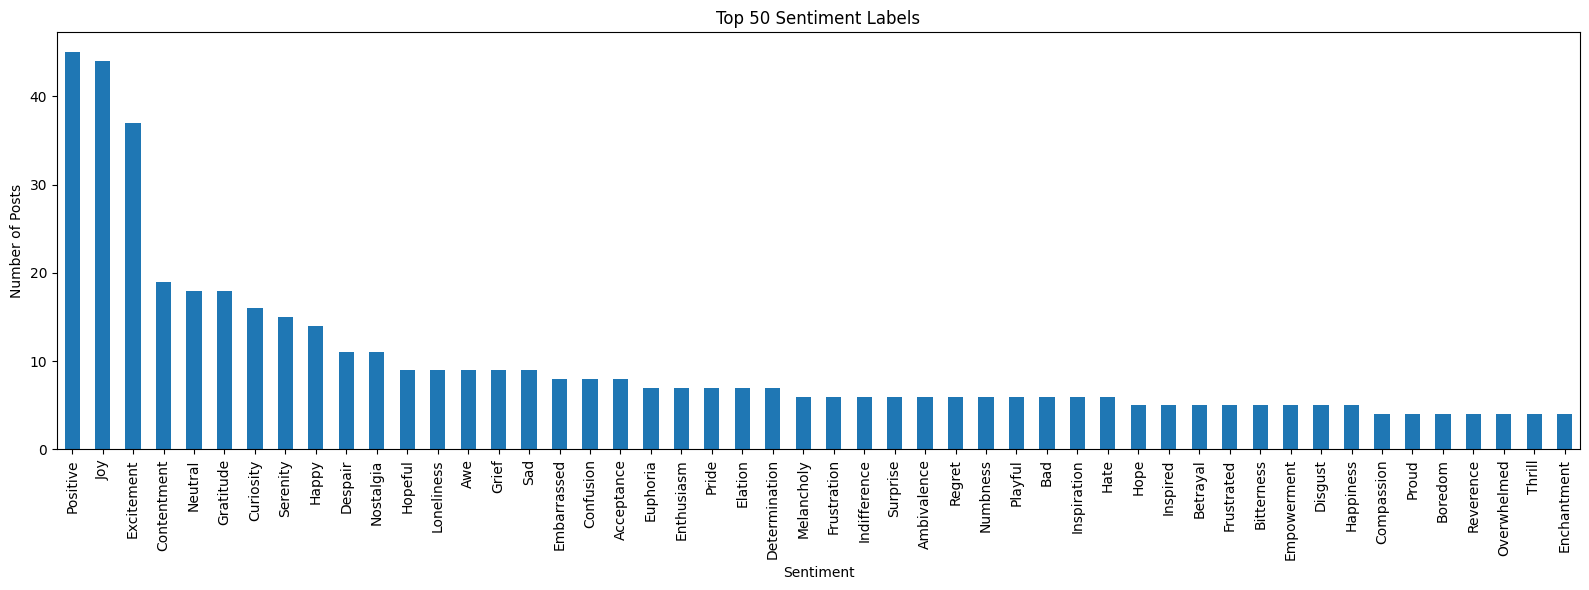

In [146]:
top50 = df['Sentiment'].value_counts().head(50)

plt.figure(figsize=(16, 6))
top50.plot(kind='bar')
plt.title('Top 50 Sentiment Labels')
plt.xlabel('Sentiment')
plt.ylabel('Number of Posts')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 2.2. Broader Sentiment Groups

The dataset contains **191 unique sentiment labels** across 732 posts, and most labels appear only once or twice. Comparing them one by one would give sparse results, so we grouped every label into one of three broader categories:

- **Positive**: pleasant emotions (e.g., Joy, Gratitude, Excitement, Admiration)
- **Negative**: unpleasant emotions (e.g., Anger, Sadness, Fear, Frustration)
- **Neutral**: emotions with mixed or no clear feelings (e.g., Nostalgia, Surprise, Reflection)

In [147]:
positive = [
    'Positive', 'Joy', 'Excitement', 'Contentment', 'Gratitude',
    'Serenity', 'Happy', 'Hopeful', 'Love', 'Euphoria',
    'Enthusiasm', 'Pride', 'Awe', 'Hope', 'Thrill', 'Happiness',
    'Elation', 'Determination', 'Playful', 'Inspiration',
    'Inspired', 'Empowerment', 'Compassion', 'Proud',
    'Reverence', 'Enchantment', 'Compassionate', 'Tenderness',
    'Fulfillment', 'Grateful', 'Admiration', 'Calmness',
    'Amusement', 'Accomplishment', 'Satisfaction', 'Adventure',
    'Wonder', 'Harmony', 'Empathetic', 'Creativity',
    'Kind', 'Confident', 'Free-spirited', 'Zest',
    'Affection', 'Enjoyment', 'Adoration', 'Rejuvenation',
    'Resilience', 'Coziness', 'Tranquility', 'Whimsy',
    'Radiance', 'Captivation', 'Optimism', 'Motivation',
    'JoyfulReunion', 'Overjoyed', 'Wonderment', 'Appreciation',
    'Confidence', 'Blessed', 'Elegance', 'Marvel',
    'Spark', 'Freedom', 'Dazzle', 'DreamChaser',
    'PlayfulJoy', 'Amazement', 'Success', 'Friendship',
    'Romance', 'Grandeur', 'Energy', 'Celebration',
    'Charm', 'Ecstasy', 'Positivity', 'Kindness',
    'Touched', 'Connection', 'Triumph', 'Solace',
    'Heartwarming', 'Sympathy', 'Renewed Effort',
    'Mesmerizing', 'Vibrancy', 'Imagination', 'Breakthrough',
    'Relief',
    'Melodic', 'FestiveJoy', 'Adrenaline', 'ArtisticBurst', 'CulinaryOdyssey',
    'Immersion', 'Colorful', 'Hypnotic', 'Joy in Baking', 'Culinary Adventure',
    'Winter Magic', 'Thrilling Journey', "Nature's Beauty", 'Celestial Wonder',
    'Creative Inspiration', 'Runway Creativity', "Ocean's Freedom"
]

negative = [
    'Negative', 'Sad', 'Anger', 'Grief', 'Loneliness',
    'Embarrassed', 'Regret', 'Frustration', 'Fear',
    'Bad', 'Hate', 'Betrayal', 'Disgust', 'Sadness',
    'Despair', 'Melancholy', 'Frustrated', 'Bitterness',
    'Boredom', 'Overwhelmed', 'Desolation', 'Shame',
    'Dismissive', 'Heartbreak', 'Devastated', 'Jealous',
    'Jealousy', 'Resentment', 'Bitter', 'Envious',
    'Fearful', 'Helplessness', 'Intimidation', 'Anxiety',
    'Envy', 'Disappointed', 'Disappointment', 'Sorrow',
    'Loss', 'Apprehensive', 'Isolation', 'Suffering',
    'Heartache', 'Desperation', 'Darkness', 'Exhaustion',
    'LostLove', 'Obstacle', 'Pressure', 'Miscalculation',
    'Yearning', 'EmotionalStorm', 'Ruins'
]

neutral = [
    'Neutral', 'Curiosity', 'Nostalgia', 'Acceptance',
    'Confusion', 'Ambivalence', 'Numbness', 'Indifference',
    'Surprise', 'Reflection', 'Anticipation', 'Exploration',
    'Mischievous', 'Emotion', 'Contemplation', 'Intrigue',
    'Bittersweet', 'Pensive', 'Mindfulness', 'InnerJourney',
    'Solitude', 'Engagement', 'Journey', 'Iconic',
    'Suspense', 'Challenge', 'Arousal',
    'Envisioning History', 'Whispers of the Past'
]

def group_sentiment(sentiment):
  if sentiment in positive:
      return 'Positive'
  elif sentiment in negative:
      return 'Negative'
  elif sentiment in neutral:
      return 'Neutral'
  else:
      return 'Others'

df['Sentiment_Group'] = df['Sentiment'].apply(group_sentiment)
print(df['Sentiment_Group'].value_counts())

Sentiment_Group
Positive    434
Negative    181
Neutral     117
Name: count, dtype: int64


### 2.2.1. Sentiment Group Distribution

The pie chart below shows the share of posts in each group. This tells us whether social media content in our data leans positive or negative, and gives a baseline for the later sections, where we check whether this balance changes by platform, time and country.

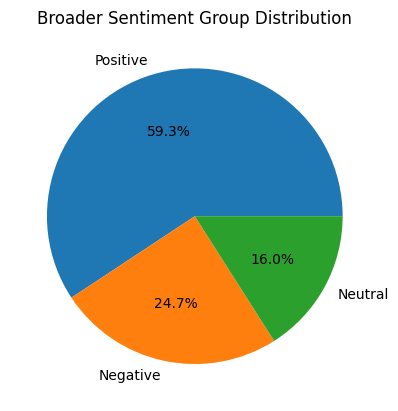

In [148]:
sentiments = df['Sentiment_Group'].value_counts()

plt.pie(sentiments, labels=sentiments.index, autopct='%1.1f%%')

plt.title('Broader Sentiment Group Distribution')

plt.show()

### 3. Sentiment vs. Engagement

Determine which sentiments receive higher likes and retweets by combining them into a single column `Total_Engagement`.

In [149]:
df['Total_Engagement'] = df['Likes'] + df['Retweets']

print(df[['Likes', 'Retweets', 'Total_Engagement']])

     Likes  Retweets  Total_Engagement
0     30.0      15.0              45.0
1     10.0       5.0              15.0
2     40.0      20.0              60.0
3     15.0       8.0              23.0
4     25.0      12.0              37.0
..     ...       ...               ...
727   39.0      20.0              59.0
728   48.0      25.0              73.0
729   42.0      22.0              64.0
730   43.0      21.0              64.0
731   47.0      24.0              71.0

[732 rows x 3 columns]


In [150]:
df_main = df[df['Sentiment_Group'] != 'Others'].copy() #exclude Others

### 3.1. Average `Likes` by Sentiment Group

In [151]:
avg_likes = df_main.groupby('Sentiment_Group')['Likes'].mean()

print(avg_likes)

Sentiment_Group
Negative    36.038674
Neutral     40.880342
Positive    46.308756
Name: Likes, dtype: float64


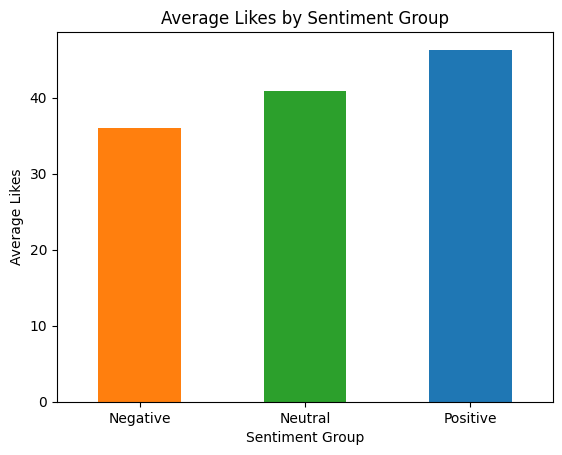

In [152]:
avg_likes.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Average Likes by Sentiment Group')
plt.xlabel('Sentiment Group')
plt.ylabel('Average Likes')
plt.xticks(rotation=0)

plt.show()

### 3.2. Average `Retweets` by Sentiment Group

In [153]:
avg_retweets = df_main.groupby('Sentiment_Group')['Retweets'].mean()
print(avg_retweets)

Sentiment_Group
Negative    18.055249
Neutral     20.504274
Positive    23.218894
Name: Retweets, dtype: float64


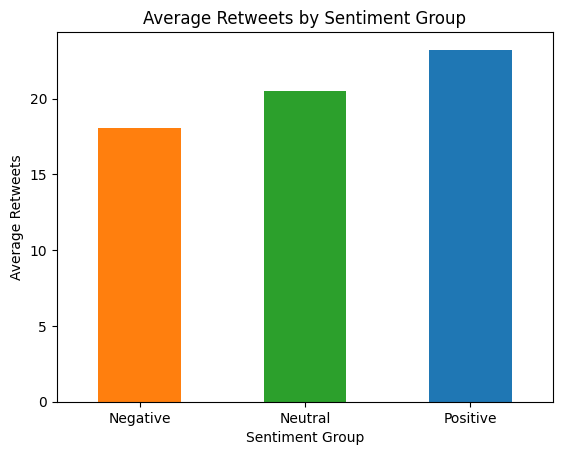

In [154]:
avg_retweets.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Average Retweets by Sentiment Group')
plt.xlabel('Sentiment Group')
plt.ylabel('Average Retweets')
plt.xticks(rotation=0)

plt.show()

### 3.3. Average `Total_Engagement` by Sentiment Group

In [155]:
avg_engagement = df_main.groupby('Sentiment_Group')['Total_Engagement'].mean()
print(avg_engagement)

Sentiment_Group
Negative    54.093923
Neutral     61.384615
Positive    69.527650
Name: Total_Engagement, dtype: float64


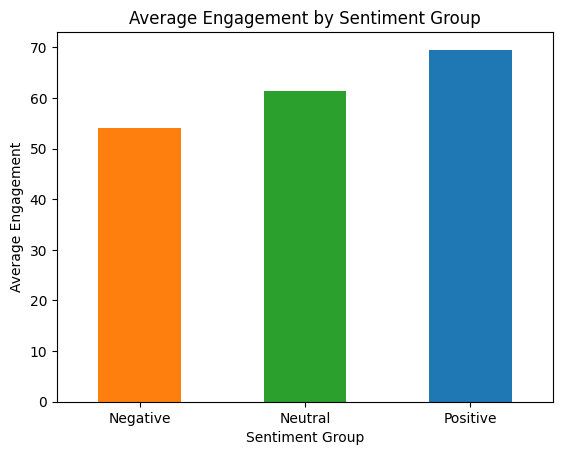

In [156]:
avg_engagement.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Average Engagement by Sentiment Group')
plt.xlabel('Sentiment Group')
plt.ylabel('Average Engagement')
plt.xticks(rotation=0)

plt.show()

**Takeaway:** Positive posts receive the most engagement: about **69.5** likes + retweets per post, vs. 61.4 for neutral and 54.1 for negative. That is roughly **29% more engagement than negative posts**. The same ranking (positive > neutral > negative) holds for likes and retweets separately.

### 4. Platform vs. Sentiment

The dataset covers three platforms: Facebook, Instagram and Twitter. In this section we check whether users behave differently on each platform.

### 4.1. Sentiment Counts by Platform

We first count the number of posts in each sentiment group for every platform.

In [157]:
platform_sentiment = (df_main.groupby(['Platform', 'Sentiment_Group']).size().unstack(fill_value=0))
print(platform_sentiment)

Sentiment_Group  Negative  Neutral  Positive
Platform                                    
Facebook               57       34       140
Instagram              60       47       151
Twitter                64       36       143


### 4.2. Sentiment Share by Platform

Raw counts are hard to compare because each platform has a different number of posts. We convert each row into percentages, so every platform adds up to 100%.

In [158]:
platform_sentiment_percent = (platform_sentiment.div(platform_sentiment.sum(axis=1), axis=0)* 100)
print(platform_sentiment_percent.round(2))

Sentiment_Group  Negative  Neutral  Positive
Platform                                    
Facebook            24.68    14.72     60.61
Instagram           23.26    18.22     58.53
Twitter             26.34    14.81     58.85


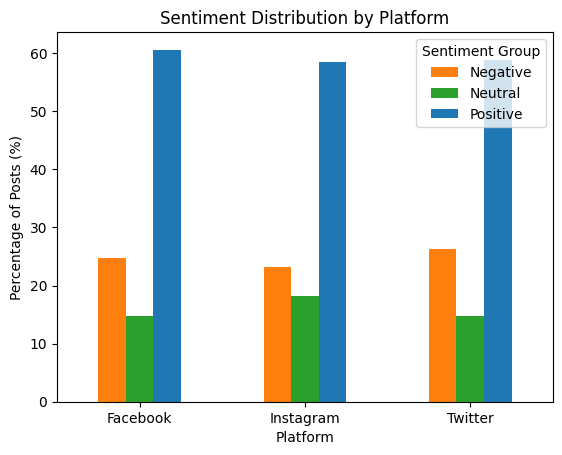

In [184]:
platform_sentiment_percent.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Sentiment Distribution by Platform')
plt.xlabel('Platform')
plt.ylabel('Percentage of Posts (%)')
plt.xticks(rotation=0)
plt.legend(title='Sentiment Group')

plt.show()

**Takeaway:** The sentiment mix is almost identical across platforms: about 59-61% of posts are positive, 15-18% neutral and 23-26% negative on Facebook, Instagram and Twitter. The differences are only a few percentage points, which suggests that **the platform does not meaningfully affect the emotional tone of what people post**.

### 5. Cross-Feature Analysis (Platform x Sentiment x Engagement)

In section 3 we found that positive posts receive more engagement than negative ones. Here we check whether this relationship **holds on every platform**, or whether it is stronger on some platforms than others.

### 5.1. Average Engagement by Platform and Sentiment Group

In [160]:
engagement_pivot = df_main.pivot_table(index='Platform', columns='Sentiment_Group', values='Total_Engagement', aggfunc='mean')
print(engagement_pivot.round(2))

Sentiment_Group  Negative  Neutral  Positive
Platform                                    
Facebook            53.68    57.47     67.87
Instagram           56.27    65.09     73.04
Twitter             52.42    60.25     67.44


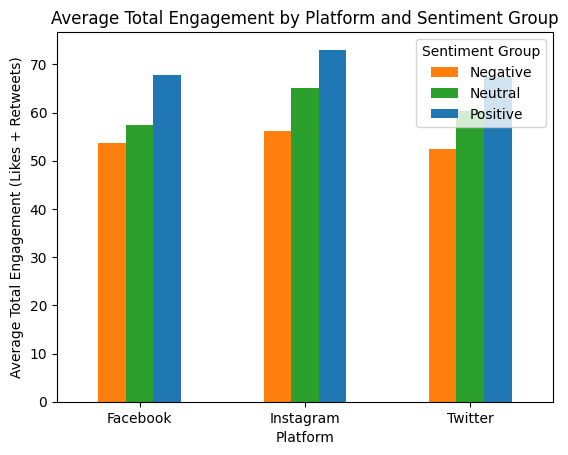

In [161]:
engagement_pivot.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Average Total Engagement by Platform and Sentiment Group')
plt.xlabel('Platform')
plt.ylabel('Average Total Engagement (Likes + Retweets)')
plt.xticks(rotation=0)
plt.legend(title='Sentiment Group')

plt.show()

### 5.2. Positive vs. Negative by Platform

How much more engagement do "Positive" posts get than "Negative" posts on each platform?

In [162]:
gap = pd.DataFrame({
    'Positive': engagement_pivot['Positive'],
    'Negative': engagement_pivot['Negative']
})
gap['Difference'] = gap['Positive'] - gap['Negative']
gap['Positive vs Negative (%)'] = gap['Difference'] / gap['Negative'] * 100

print(gap.round(1))

           Positive  Negative  Difference  Positive vs Negative (%)
Platform                                                           
Facebook       67.9      53.7        14.2                      26.4
Instagram      73.0      56.3        16.8                      29.8
Twitter        67.4      52.4        15.0                      28.6


**Takeaway:** Positive posts get 25 to 30 percent more engagement than negative posts on every platform (Facebook, Instagram and Twitter). So the sentiment-engagement link is consistent across platforms: tone matters about equally everywhere. Instagram has the highest engagement overall.

### 6. Temporal Analysis

In this section we look at whether the emotional tone of posts changes over time, at three levels: **by year** (long-term trend), **by time of day** (daily pattern) and **by season** (yearly cycle).

### 6.1. Time Range of the Data

We first check the period covered by the dataset and how many posts fall in each year.

In [163]:
df_main['Timestamp'] = pd.to_datetime(df_main['Timestamp'])

print("From:", df_main['Timestamp'].min())
print("To:  ", df_main['Timestamp'].max())
print()
print(df_main['Year'].value_counts().sort_index())

From: 2010-05-15 15:30:00
To:   2023-10-22 20:45:00

Year
2010      3
2011      4
2012      4
2013      4
2014      4
2015     19
2016     38
2017     43
2018     56
2019     73
2020     69
2021     63
2022     63
2023    289
Name: count, dtype: int64


The data spans 2010 to 2023, but posts are very unevenly distributed: 2010-2014 have only 3-4 posts each, while 2023 alone has 289 posts (about 40% of the dataset).

### 6.2. Sentiment Share by Year

In [187]:
year_sentiment = pd.crosstab(df_main['Year'], df_main['Sentiment_Group'], normalize='index') * 100
print(year_sentiment.round(1))

Sentiment_Group  Negative  Neutral  Positive
Year                                        
2010                  0.0      0.0     100.0
2011                  0.0      0.0     100.0
2012                  0.0      0.0     100.0
2013                  0.0      0.0     100.0
2014                  0.0      0.0     100.0
2015                 21.1     21.1      57.9
2016                 31.6     13.2      55.3
2017                 34.9     20.9      44.2
2018                 32.1     14.3      53.6
2019                 31.5     16.4      52.1
2020                 23.2     11.6      65.2
2021                 28.6     12.7      58.7
2022                 27.0     20.6      52.4
2023                 20.1     17.3      62.6


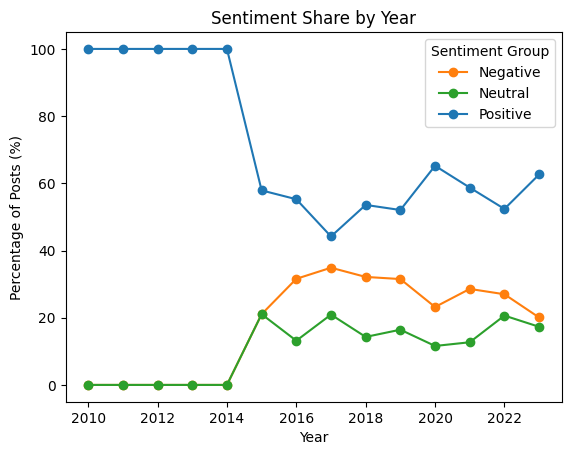

In [188]:
year_sentiment.plot(kind='line', marker='o', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Sentiment Share by Year')
plt.xlabel('Year')
plt.ylabel('Percentage of Posts (%)')
plt.legend(title='Sentiment Group')

plt.show()

  **Takeaway:** 2010-2014 show 100% positive, but with only 3-4 posts per year these values are not meaningful. From 2015 on, positive posts are the majority in every year, but there is no clear upward or downward trend: …

### 6.3. Sentiment Share by Time of Day

We group posting hours into four periods: Morning (5-12), Afternoon (12-17), Evening (17-21) and Night (21-5).

In [166]:
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df_main['Time_of_Day'] = df_main['Hour'].apply(get_time_of_day)
time_order = ['Morning', 'Afternoon', 'Evening', 'Night']

time_sentiment = pd.crosstab(df_main['Time_of_Day'], df_main['Sentiment_Group'], normalize='index') * 100
time_sentiment = time_sentiment.loc[time_order]
print(time_sentiment.round(1))

Sentiment_Group  Negative  Neutral  Positive
Time_of_Day                                 
Morning              23.1     21.5      55.4
Afternoon            23.7     16.5      59.7
Evening              23.1     12.2      64.7
Night                34.9     16.3      48.8


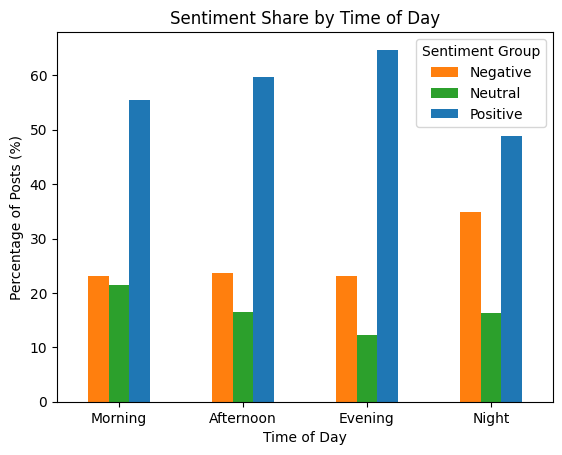

In [167]:
time_sentiment.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Sentiment Share by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Percentage of Posts (%)')
plt.xticks(rotation=0)
plt.legend(title='Sentiment Group')

plt.show()

**Takeaway:** Positivity rises through the day, from 55% in the morning to 65% in the evening. Night is the exception: it has the lowest positive share (49%) and the highest negative share (35%). However, night has the fewest posts (86), so this pattern should be treated as a tendency rather than a firm conclusion.

### 6.4. Sentiment and Engagement by Season

We group months into seasons (Winter: Dec-Feb, Spring: Mar-May, Summer: Jun-Aug, Fall: Sep-Nov) and compare both the sentiment mix and the average engagement.

In [168]:
# Map months to seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df_main['Season'] = df_main['Month'].apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Fall']

# Sentiment share by season
season_sentiment = pd.crosstab(df_main['Season'], df_main['Sentiment_Group'], normalize='index') * 100
season_sentiment = season_sentiment.loc[season_order]
print(season_sentiment.round(1))

Sentiment_Group  Negative  Neutral  Positive
Season                                      
Winter               24.3     13.6      62.1
Spring               27.0     19.1      53.9
Summer               18.5     13.3      68.2
Fall                 31.0     19.5      49.4


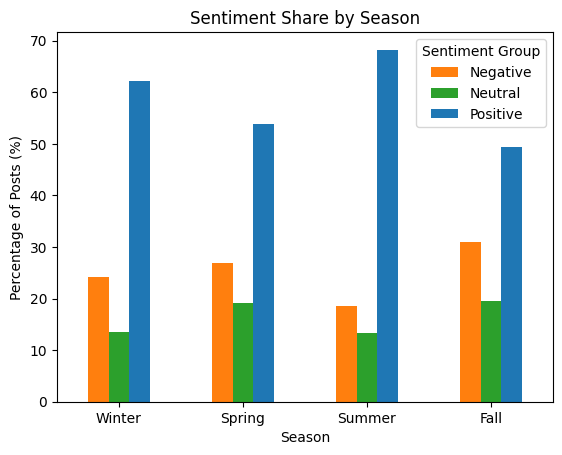

In [169]:
season_sentiment.plot(kind='bar', color=['#ff7f0e', '#2ca02c', '#1f77b4'])

plt.title('Sentiment Share by Season')
plt.xlabel('Season')
plt.ylabel('Percentage of Posts (%)')
plt.xticks(rotation=0)
plt.legend(title='Sentiment Group')

plt.show()

In [170]:
# Average engagement by season
print(df_main.groupby('Season')['Total_Engagement'].mean().loc[season_order].round(1))

Season
Winter    60.4
Spring    63.6
Summer    69.9
Fall      63.3
Name: Total_Engagement, dtype: float64


**Takeaway:** Season shows the clearest temporal pattern. **Summer is the most positive season** (68% positive, only 19% negative) and also receives the highest engagement (about 70 interactions per post). **Fall is the least positive** (49% positive, 31% negative). Winter and spring fall in between.

### 7. Hashtag Analysis

Hashtags can indicate the topics people post about. In this section we identify the most popular hashtags, check which sentiments they are associated with, and compare their engagement.

### 7.1. Splitting Hashtags

The `Hashtags` column stores all of a post's hashtags in a single string (e.g. `"#Nature #Park"`). We split it so that each row contains exactly one hashtag, keeping the post's sentiment and engagement.

In [171]:
hashtag_df = df_main[['Text', 'Hashtags', 'Sentiment', 'Sentiment_Group', 'Platform', 'Likes', 'Retweets', 'Total_Engagement']].copy()
hashtag_df['Hashtag'] = hashtag_df['Hashtags'].str.strip().str.split()
hashtag_df = hashtag_df.explode('Hashtag')

print("Total hashtag uses:", len(hashtag_df))
print("Unique hashtags:", hashtag_df['Hashtag'].nunique())

Total hashtag uses: 1464
Unique hashtags: 975


### 7.2. Top 10 Hashtags and Their Sentiment Mix

In [172]:
top10 = hashtag_df['Hashtag'].value_counts().head(10)
print(top10)

Hashtag
#Serenity       15
#Gratitude      13
#Excitement     13
#Nostalgia      11
#Despair        11
#Curiosity      10
#Contentment    10
#Hopeful         9
#Awe             9
#Grief           9
Name: count, dtype: int64


In [173]:
# Sentiment mix of the top 10 hashtags
top_df = hashtag_df[hashtag_df['Hashtag'].isin(top10.index)]

hashtag_sentiment = pd.crosstab(top_df['Hashtag'], top_df['Sentiment_Group'], normalize='index') * 100
hashtag_sentiment = hashtag_sentiment.loc[top10.index]
print(hashtag_sentiment.round(1))

Sentiment_Group  Negative  Neutral  Positive
Hashtag                                     
#Serenity             0.0      0.0     100.0
#Gratitude            0.0      0.0     100.0
#Excitement           0.0      7.7      92.3
#Nostalgia            0.0    100.0       0.0
#Despair            100.0      0.0       0.0
#Curiosity            0.0    100.0       0.0
#Contentment          0.0      0.0     100.0
#Hopeful              0.0      0.0     100.0
#Awe                  0.0      0.0     100.0
#Grief              100.0      0.0       0.0


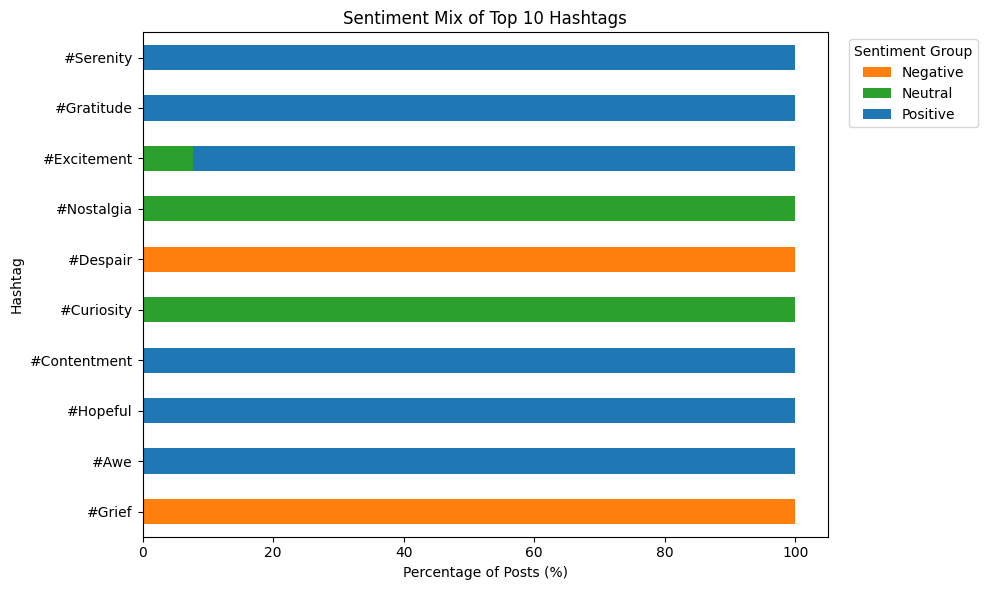

In [174]:
hashtag_sentiment.plot(kind='barh', stacked=True, color=['#ff7f0e', '#2ca02c', '#1f77b4'], figsize=(10, 6))

plt.title('Sentiment Mix of Top 10 Hashtags')
plt.xlabel('Percentage of Posts (%)')
plt.ylabel('Hashtag')
plt.legend(title='Sentiment Group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

**Takeaway:** Almost every top hashtag belongs entirely to a single sentiment group. This is expected: the top hashtags are the emotion names themselves (e.g., a post labeled "Despair" tagged #Despair), so this result mostly reflects how the dataset was labeled rather than a real link between topics and sentiment.

### 7.3. Engagement of the Top 10 Hashtags

In [175]:
# Average engagement of the top 10 hashtags
hashtag_engagement = (top_df.groupby('Hashtag')['Total_Engagement'].mean().sort_values(ascending=False))
print(hashtag_engagement.round(1))

Hashtag
#Excitement     80.1
#Contentment    73.7
#Gratitude      69.8
#Awe            66.8
#Serenity       63.5
#Grief          59.1
#Curiosity      58.2
#Nostalgia      54.4
#Despair        53.5
#Hopeful        43.3
Name: Total_Engagement, dtype: float64


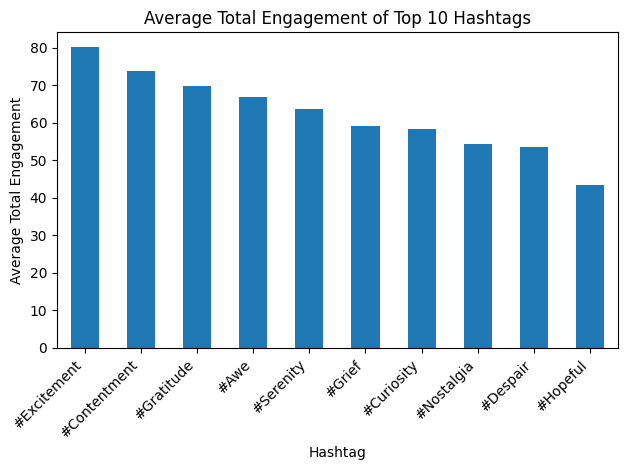

In [176]:
hashtag_engagement.plot(kind='bar', color='#1f77b4')

plt.title('Average Total Engagement of Top 10 Hashtags')
plt.xlabel('Hashtag')
plt.ylabel('Average Total Engagement')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

### 8. Country Analysis

In this section we compare posting activity, sentiment and engagement across countries. The data covers 33 countries, but most of them have only a handful of posts, so we first check how posts are distributed before making comparisons.

### 8.1. Posts and Engagement per Country

In [179]:
from PIL import Image

image_path = 'Country.png'
img = Image.open(image_path)

display(img)

FileNotFoundError: [Errno 2] No such file or directory: 'Country.png'

In [ ]:
image_path = 'Country_likes.png'
img = Image.open(image_path)

display(img)

In [ ]:
image_path = 'Country_retweets.png'
img = Image.open(image_path)

display(img)

### 9. Predictive Modeling (Optional)

Can we predict a post's engagement (likes + retweets) from its sentiment, platform, time and country? This section will be developed after the mid-program presentation.